# 05 — Um dataset astronômico multimodal

Workshop SAB — AI-Scope / ADSS

**Objetivo:** reunir, para as mesmas fontes, Gaia (astrometria e fotometria), DESI (redshift e espectros B/R/Z), ZTF DR22 (curvas de luz em todos os filtros) e cutouts S-PLUS (imagens). O manifest mantém **uma linha por fonte**; os arrays de espectros e curvas de luz ficam em arquivos separados. No fim, visualizamos uma fonte com cobertura em todas as modalidades.


## 1. Preparação

Execute este notebook a partir da pasta `notebooks/`. A amostra terá até **1.000 fontes Gaia** em um polígono centrado em **RA 0°, Dec 0°**: RA de 358° a 2° e Dec de −1° a +1°. Ajuste `MAX_OBJECTS` para o tempo disponível. Baixamos até `MAX_CUTOUTS` imagens, priorizando fontes com DESI e ZTF; as consultas aos catálogos continuam restritas à amostra.


In [17]:
import json
import os
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import adss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy.io import fits

BASE_URL = "https://ai-scope.cbpf.br/"

cl = adss.ADSSClient(base_url=BASE_URL)

OUT = Path("outputs/multimodal")
OUT.mkdir(parents=True, exist_ok=True)
MATCH_RADIUS_ARCSEC = 1.0
MAX_OBJECTS = 1000
STAMP_PIXELS = 64
MAX_CUTOUTS = 120

## 2. Escolher uma imagem S-PLUS dentro do polígono

O polígono cruza RA 0°. Procuramos, pela API de imagens, um arquivo científico `R` cujo centro esteja dentro dele. A lista pode conter mapas de peso, que não servem para os cutouts. A consulta Gaia na próxima etapa usa o polígono; a imagem escolhida serve para ordenar os objetos mais próximos de uma área com pixels.

In [18]:
collections = pd.DataFrame(cl.get_collections())
if collections.empty:
    raise RuntimeError("Nenhuma coleção de imagens disponível.")
display(collections[[x for x in ["id", "name", "description"] if x in collections]])

preferred = collections[collections["name"].str.contains("splus", case=False, na=False)]
collection = preferred.iloc[0] if not preferred.empty else collections.iloc[0]
COLLECTION_ID = int(collection["id"])

# Polígono de 4° × 2° centrado em (RA, Dec) = (0°, 0°).
POLYGON_RA_WEST, POLYGON_RA_EAST = 358.0, 2.0
POLYGON_DEC_SOUTH, POLYGON_DEC_NORTH = -1.0, 1.0

def inside_polygon_bounds(ra, dec):
    signed_ra = (float(ra) + 180.0) % 360.0 - 180.0
    return -2.0 <= signed_ra <= 2.0 and POLYGON_DEC_SOUTH <= float(dec) <= POLYGON_DEC_NORTH

candidates = cl.cone_search_images(
    collection_id=COLLECTION_ID, ra=0.0, dec=0.0,
    radius=2.5, filter_name="R", limit=100,
)
science_files = [item for item in candidates
                 if (str(item.get("filter", "")).upper() == "R"
                     and "swpweight" not in str(item.get("filename", "")).lower()
                     and pd.notna(item.get("ra_center"))
                     and pd.notna(item.get("dec_center"))
                     and inside_polygon_bounds(item["ra_center"], item["dec_center"]))]
if not science_files:
    raise RuntimeError("Nenhum arquivo R científico encontrado dentro do polígono; revise a coleção/cobertura.")
image_file = min(science_files, key=lambda item: abs((float(item["ra_center"]) + 180) % 360 - 180)
                 + abs(float(item["dec_center"])))
RA0, DEC0 = float(image_file["ra_center"]), float(image_file["dec_center"])
print({k: image_file.get(k) for k in ["id", "object_name", "filter", "ra_center", "dec_center", "pixel_scale"]})

,id,name,description
0,4,splus dr1-dr4,
1,3,splus idr6,splus idr6 collection


{'id': 155856, 'object_name': 'STRIPE82_0001', 'filter': 'R', 'ra_center': 359.99992360541097, 'dec_center': -0.699923611110481, 'pixel_scale': 0.55000000000008}


In [19]:
# Confirme as tabelas e campos essenciais na instância usada durante a aula.
metadata = cl.get_database_metadata()
tables = {f"{schema.name}.{table.name}": {col.name for col in table.columns}
          for schema in metadata.schemas for table in schema.tables}
required = {
    "public.gaia_dr3": {"source_id", "ra", "dec", "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag", "parallax", "pmra", "pmdec", "ruwe"},
    "desi.desi_specz_dr1": {"id", "ra", "dec", "z", "zwarn", "spectype", "deltachi2"},
    "desi.desi_dr1": {"targetid", "wave_b", "flux_b", "ivar_b", "wave_r", "flux_r", "ivar_r", "wave_z", "flux_z", "ivar_z"},
    "public.ztf_dr22": {"id", "ra", "dec", "filterid", "nepochs", "hmjd", "mag", "magerr"},
}
for table, columns in required.items():
    missing = columns - tables.get(table, set())
    if missing:
        raise RuntimeError(f"Esquema inesperado em {table}: faltam {sorted(missing)}")
print("Tabelas e colunas essenciais confirmadas.")

Tabelas e colunas essenciais confirmadas.


## 3. Gaia: a lista principal de objetos

A consulta usa `polygon(ra, dec, ...)` do AstroQL. Os vértices vão de RA 358° a 2°, atravessando o meridiano 0°, e de Dec −1° a +1°. Ordenamos pela distância ao centro da imagem S-PLUS escolhida; assim os primeiros alvos têm maior chance de produzir cutouts. `TOP` limita a aula, mas essa seleção por proximidade **não é uma amostra representativa** do polígono.
Escreva a consulta Gaia com as colunas usadas no manifest (`source_id`, RA/Dec, fotometria G/BP/RP, paralaxe/erro, movimentos próprios, `ruwe`) e `image_distance_deg = dist(ra, dec, RA0, DEC0)`. Aplique o polígono que atravessa RA 0°, exija G não nula, ordene por distância e limite a `MAX_OBJECTS`.


In [ ]:
gaia_query = None  # Complete a consulta AstroQL do enunciado.
if gaia_query is None:
    raise NotImplementedError("Complete gaia_query; veja outputs/respostas.txt após tentar.")
gaia = cl.query_and_wait(query_text=gaia_query, mode="astroql", verbose=0).data.copy()
if gaia.empty:
    raise RuntimeError("Nenhuma fonte Gaia no polígono; confira coordenadas e cobertura da tabela.")
gaia["object_id"] = "gaia_" + gaia["source_id"].astype(str)
if not gaia.object_id.is_unique:
    raise RuntimeError("A consulta Gaia retornou IDs repetidos.")
objects = gaia[["object_id", "ra", "dec"]].copy()
print(f"Fontes Gaia: {len(objects)}")
display(gaia.head())

## 4. DESI: espectroscopia por posição

Enviamos as coordenadas Gaia como tabela temporária e buscamos pares a até 1 arcsec. Se houver vários candidatos, guardamos o mais próximo e registramos quantos havia. Mesmo uma associação próxima pode ser incorreta; a flag de qualidade também exige `zwarn = 0`.
Escreva a consulta que associa `upload.objects` a `desi.desi_specz_dr1` dentro de `MATCH_RADIUS_ARCSEC / 3600` graus. Retorne `object_id`, ID/posição DESI, `z`, `zerr`, `zwarn`, `spectype`, `subtype`, `deltachi2` e `desi_sep_deg`. `zwarn = 0` será usado mais adiante como parte do critério de redshift seguro.


In [ ]:
desi_query = None  # Complete a consulta AstroQL do enunciado.
if desi_query is None:
    raise NotImplementedError("Complete desi_query; veja outputs/respostas.txt após tentar.")
raw_desi = cl.query_and_wait(
    query_text=desi_query, mode="astroql", file=objects,
    table_name="objects", verbose=0,
).data.copy()

expected = ["object_id", "desi_id", "desi_ra", "desi_dec", "z", "zerr", "zwarn",
            "spectype", "subtype", "deltachi2", "desi_sep_deg"]
if raw_desi.empty:
    raw_desi = pd.DataFrame(columns=expected)
raw_desi["desi_id"] = raw_desi["desi_id"].astype("string")
raw_desi["desi_sep_arcsec"] = pd.to_numeric(raw_desi["desi_sep_deg"], errors="coerce") * 3600
candidate_counts = raw_desi.groupby("object_id").size().rename("n_desi_candidates")
desi_best = (raw_desi.sort_values(["object_id", "desi_sep_arcsec", "desi_id"])
             .drop_duplicates("object_id")
             .merge(candidate_counts, on="object_id", validate="one_to_one"))
print(f"Associações DESI: {len(raw_desi)}; objetos com candidato: {len(desi_best)}; "
      f"objetos ambíguos: {(candidate_counts > 1).sum()}")
display(desi_best.head())

### Buscar os espectros DESI

`desi.desi_specz_dr1.id` corresponde a `desi.desi_dr1.targetid`. Consultamos apenas os IDs selecionados para o manifest e mantemos os arrays B/R/Z fora do CSV.

Associe `upload.desitargets` a `desi.desi_dr1` por `desi_id = targetid` e traga os arrays `wave_*`, `flux_*`, `ivar_*` das bandas B/R/Z. `ivar > 0` indica pixels com peso utilizável; não confunda os braços espectrais com magnitudes fotométricas.


In [ ]:
desi_spectra_query = None  # Complete a consulta AstroQL do enunciado.
if desi_spectra_query is None:
    raise NotImplementedError("Complete desi_spectra_query; veja outputs/respostas.txt após tentar.")
desi_targets = desi_best[["desi_id"]].drop_duplicates().astype("int64")
if desi_targets.empty:
    spectra = pd.DataFrame(columns=["desi_id"] + [
        f"{quantity}_{arm}" for arm in ("b", "r", "z")
        for quantity in ("wave", "flux", "ivar")
    ])
else:
    spectra = cl.query_and_wait(
        query_text=desi_spectra_query, mode="astroql", file=desi_targets,
        table_name="desitargets", verbose=0,
    ).data.copy()
if spectra.empty:
    spectra = pd.DataFrame(columns=["desi_id"] + [
        f"{quantity}_{arm}" for arm in ("b", "r", "z")
        for quantity in ("wave", "flux", "ivar")
    ])
spectra["desi_id"] = spectra["desi_id"].astype("string")

def has_valid_spectrum(row):
    for arm in ("b", "r", "z"):
        values = [row[f"{quantity}_{arm}"] for quantity in ("wave", "flux", "ivar")]
        if any(value is None for value in values):
            continue
        wave, flux, ivar = (np.asarray(value, dtype=float) for value in values)
        if wave.ndim != 1 or wave.shape != flux.shape or wave.shape != ivar.shape:
            continue
        if (np.isfinite(wave) & np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)).any():
            return True
    return False

spectra["has_valid_flux"] = spectra.apply(has_valid_spectrum, axis=1) if not spectra.empty else pd.Series(dtype=bool)
valid_spectra_ids = set(spectra.loc[spectra.has_valid_flux, "desi_id"])
print(f"Espectros DESI retornados: {len(spectra)}; com fluxo válido: {spectra.has_valid_flux.sum()}")


## 5. ZTF DR22: a dimensão temporal

A tabela ZTF guarda tempos (`hmjd`), magnitudes (`mag`) e erros (`magerr`) em arrays. Buscamos as fontes ZTF próximas dos mesmos objetos Gaia. O manifest usa uma linha por objeto para resumir a cobertura; `raw_ztf` preserva **todas** as linhas e filtros para o arquivo de curvas de luz e para o gráfico final.

Escreva a consulta que associa `upload.objects` a `public.ztf_dr22` dentro do mesmo raio angular. Retorne `object_id`, ID/posição ZTF, `filterid`, `nepochs`, os arrays `hmjd`, `mag`, `magerr` e a separação `ztf_sep_deg`. Mantenha todas as linhas para preservar filtros diferentes.


In [ ]:
ztf_query = None  # Complete a consulta AstroQL do enunciado.
if ztf_query is None:
    raise NotImplementedError("Complete ztf_query; veja outputs/respostas.txt após tentar.")
raw_ztf = cl.query_and_wait(
    query_text=ztf_query, mode="astroql", file=objects,
    table_name="objects", verbose=0,
).data.copy()
expected_ztf = ["object_id", "ztf_id", "ztf_ra", "ztf_dec", "filterid",
                "nepochs", "hmjd", "mag", "magerr", "ztf_sep_deg"]
if raw_ztf.empty:
    raw_ztf = pd.DataFrame(columns=expected_ztf)
raw_ztf["ztf_id"] = raw_ztf["ztf_id"].astype("string")
raw_ztf["ztf_sep_arcsec"] = pd.to_numeric(raw_ztf["ztf_sep_deg"], errors="coerce") * 3600
raw_ztf["nepochs"] = pd.to_numeric(raw_ztf["nepochs"], errors="coerce")
ztf_counts = raw_ztf.groupby("object_id").size().rename("n_ztf_candidates")
ztf_best = (raw_ztf.sort_values(["object_id", "ztf_sep_arcsec", "nepochs"],
                                ascending=[True, True, False])
            .drop_duplicates("object_id")
            .merge(ztf_counts, on="object_id", validate="one_to_one"))
print(f"Linhas ZTF: {len(raw_ztf)}; objetos com ZTF: {len(ztf_best)}; "
      f"objetos com mais de uma linha: {(ztf_counts > 1).sum()}")
display(ztf_best[["object_id", "ztf_id", "filterid", "nepochs",
                  "ztf_sep_arcsec", "n_ztf_candidates"]].head())

### Resumir cada curva de luz

A amplitude entre os percentis 5 e 95 é uma descrição simples da variabilidade. Não é um teste de variabilidade: erros, artefatos, filtro e cadência precisam ser analisados. Exigimos pelo menos cinco medidas finitas com erro positivo.
`np.percentile` calcula os quantis 5 e 95 da curva após remover valores inválidos; sua diferença é uma amplitude robusta contra extremos isolados. Ela ainda pode misturar ruído e variabilidade real, então os erros e filtros precisam ser examinados.


In [25]:
def curve_summary(row):
    t = np.asarray(row["hmjd"], dtype=float)
    mag = np.asarray(row["mag"], dtype=float)
    err = np.asarray(row["magerr"], dtype=float)
    if not (len(t) == len(mag) == len(err)):
        return pd.Series({"ztf_n_valid": 0, "ztf_median_mag": np.nan, "ztf_amp90": np.nan})
    good = np.isfinite(t) & np.isfinite(mag) & np.isfinite(err) & (err > 0)
    values = mag[good]
    if len(values) < 5:
        return pd.Series({"ztf_n_valid": len(values), "ztf_median_mag": np.nan, "ztf_amp90": np.nan})
    return pd.Series({"ztf_n_valid": len(values),
                      "ztf_median_mag": np.median(values),
                      "ztf_amp90": np.percentile(values, 95) - np.percentile(values, 5)})

ztf_features = (pd.concat([ztf_best.drop(columns=["hmjd", "mag", "magerr"]),
                           ztf_best.apply(curve_summary, axis=1)], axis=1)
                if not ztf_best.empty else
                pd.DataFrame(columns=["object_id", "ztf_id", "filterid", "nepochs",
                                      "ztf_sep_arcsec", "n_ztf_candidates",
                                      "ztf_n_valid", "ztf_median_mag", "ztf_amp90"]))
display(ztf_features[["object_id", "ztf_n_valid", "ztf_median_mag", "ztf_amp90"]].head())

,object_id,ztf_n_valid,ztf_median_mag,ztf_amp90
0,gaia_2449821690344555904,76.0,20.841017,1.194982
1,gaia_2449821754768511488,331.0,19.324398,0.304054
2,gaia_2449821789128250752,246.0,20.131684,0.580654
3,gaia_2449821823488806144,110.0,21.029042,0.753365
4,gaia_2449823953792171264,38.0,19.702396,0.254775


## 6. Juntar tudo: uma linha por fonte Gaia

As associações DESI e ZTF são opcionais. Um campo vazio significa que aquela modalidade não foi encontrada; não representa valor físico zero. Verificamos a unicidade após cada redução de candidatos.

In [26]:
manifest = gaia.merge(desi_best, on="object_id", how="left", validate="one_to_one")
manifest = manifest.merge(ztf_features, on="object_id", how="left", validate="one_to_one")
manifest["n_desi_candidates"] = manifest["n_desi_candidates"].fillna(0).astype(int)
manifest["n_ztf_candidates"] = manifest["n_ztf_candidates"].fillna(0).astype(int)
manifest["has_desi"] = manifest["desi_id"].notna()
manifest["has_desi_spectrum"] = manifest["desi_id"].isin(valid_spectra_ids)
manifest["has_ztf"] = manifest["ztf_id"].notna()
ztf_filter_counts = raw_ztf.groupby("object_id")["filterid"].nunique()
manifest["n_ztf_filters"] = manifest["object_id"].map(ztf_filter_counts).fillna(0).astype(int)
manifest["has_good_astrometry"] = pd.to_numeric(manifest["ruwe"], errors="coerce").lt(1.4) & manifest["parallax"].notna()
manifest["has_secure_desi_z"] = (manifest["has_desi"]
                                  & pd.to_numeric(manifest["zwarn"], errors="coerce").eq(0)
                                  & manifest["z"].notna()
                                  & manifest["n_desi_candidates"].eq(1))
manifest["bp_minus_rp"] = manifest["phot_bp_mean_mag"] - manifest["phot_rp_mean_mag"]
manifest["image_collection_id"] = COLLECTION_ID
manifest["image_file_id"] = int(image_file["id"])
manifest["image_filter"] = str(image_file["filter"])
manifest["stamp_size_px"] = STAMP_PIXELS
manifest["stamp_path"] = pd.NA
manifest["stamp_status"] = "not_requested"
assert len(manifest) == len(objects) and manifest.object_id.is_unique
print(f"Manifest: {len(manifest)} objetos, {manifest.has_desi.sum()} com DESI, {manifest.has_ztf.sum()} com ZTF")
display(manifest[["object_id", "phot_g_mean_mag", "bp_minus_rp", "desi_id",
                  "ztf_id", "ztf_n_valid", "ztf_amp90"]].head(10))

Manifest: 1000 objetos, 126 com DESI, 908 com ZTF


,object_id,phot_g_mean_mag,bp_minus_rp,desi_id,ztf_id,ztf_n_valid,ztf_amp90
0,gaia_2449850960546191232,19.797432,2.539209,<NA>,1492206400014544,44.0,0.510444
1,gaia_2449850479509840896,18.737270,1.862045,<NA>,1492206400006980,51.0,0.121466
2,gaia_2449850689964579584,15.303093,1.907215,<NA>,1492206400006747,54.0,0.057455
3,gaia_2449851338503315712,18.063745,2.560847,<NA>,1492206400006471,54.0,0.105201
4,gaia_2449851269783834624,20.674437,1.707715,<NA>,1492206400014588,26.0,0.611986
5,gaia_2449851716461076736,20.894098,0.298544,<NA>,1492206400006460,37.0,0.532602
6,gaia_2449850685668514304,20.761002,1.619024,<NA>,1492206400006712,26.0,0.603799
7,gaia_2449851716460836608,19.592205,1.933189,<NA>,1492206400014447,50.0,0.285082
8,gaia_2449850445150500224,19.116056,2.749333,<NA>,1492206400007085,49.0,0.258702
9,gaia_2449851067921701504,17.292448,1.861641,<NA>,1492106400004076,48.0,0.206565


## 7. Imagens: exemplos com cobertura conjunta

Baixamos até `MAX_CUTOUTS` cutouts FITS do arquivo `R`. Fontes com espectro DESI e curva ZTF são priorizadas para aumentar a chance de mostrar todas as modalidades no mesmo objeto. O status diferencia imagem disponível, não requisitada e falha.


In [27]:
image_dir = OUT / "images"
image_dir.mkdir(exist_ok=True)
stamp_targets = (manifest.assign(_overlap=manifest.has_desi_spectrum & manifest.has_ztf)
                 .sort_values(["_overlap", "image_distance_deg"], ascending=[False, True])
                 .head(MAX_CUTOUTS))
for idx, row in stamp_targets.iterrows():
    try:
        stamp_bytes = cl.create_stamp(
            file_id=int(image_file["id"]), ra=float(row["ra"]), dec=float(row["dec"]),
            size=STAMP_PIXELS, size_unit="pixels", format="fits",
        )
        with fits.open(BytesIO(stamp_bytes)) as hdul:
            plane = next((hdu.data for hdu in hdul if hdu.data is not None), None)
            if plane is None or not np.isfinite(plane).any():
                raise ValueError("cutout sem pixels finitos")
        path = image_dir / f"{row['object_id']}_R.fits"
        path.write_bytes(stamp_bytes)
        manifest.loc[idx, "stamp_path"] = str(path)
        manifest.loc[idx, "stamp_status"] = "available"
    except Exception as exc:
        manifest.loc[idx, "stamp_status"] = f"failed: {type(exc).__name__}"

manifest["has_full_multimodal"] = (manifest.has_desi_spectrum & manifest.has_ztf
                                   & manifest.stamp_status.eq("available"))
print(manifest.stamp_status.value_counts())
print(f"Fontes com Gaia, espectro DESI, ZTF e cutout: {manifest.has_full_multimodal.sum()}")
display(manifest.loc[stamp_targets.index, ["object_id", "stamp_path", "stamp_status"]].head(MAX_CUTOUTS))


stamp_status
not_requested    880
available        120
Name: count, dtype: int64
Fontes com Gaia, espectro DESI, ZTF e cutout: 98


,object_id,stamp_path,stamp_status
15,gaia_2449852128778483328,outputs/multimodal/images/gaia_244985212877848...,available
19,gaia_2449849315575044480,outputs/multimodal/images/gaia_244984931557504...,available
40,gaia_2449851858195682944,outputs/multimodal/images/gaia_244985185819568...,available
51,gaia_2449850342071298048,outputs/multimodal/images/gaia_244985034207129...,available
59,gaia_2449845669146456576,outputs/multimodal/images/gaia_244984566914645...,available
...,...,...,...
18,gaia_2449847662011297920,outputs/multimodal/images/gaia_244984766201129...,available
20,gaia_2449847528868650752,outputs/multimodal/images/gaia_244984752886865...,available
21,gaia_2449852133073590272,outputs/multimodal/images/gaia_244985213307359...,available
22,gaia_2449852128777306240,outputs/multimodal/images/gaia_244985212877730...,available


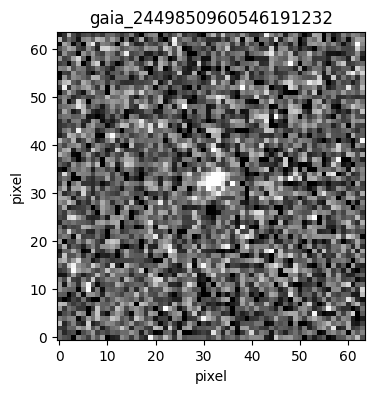

In [28]:
available = manifest[manifest.stamp_status.eq("available")]
if not available.empty:
    with fits.open(available.iloc[0].stamp_path) as hdul:
        image = next(hdu.data for hdu in hdul if hdu.data is not None)
    lo, hi = np.nanpercentile(image, [5, 99.5])
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(image, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax.set(title=available.iloc[0].object_id, xlabel="pixel", ylabel="pixel")
    plt.show()
else:
    print("Nenhum cutout disponível; revise campo, cobertura e resposta do serviço.")

## 8. Visualizar o dataset

Os gráficos de cobertura mostram seleção e dados ausentes. Em seguida, escolhemos uma fonte com Gaia, espectro DESI, ZTF e cutout S-PLUS e mostramos todas essas modalidades. Magnitudes menores são mais brilhantes.

No painel conjunto, as magnitudes Gaia são pontos por banda, a curva ZTF usa barras de erro (`matplotlib.errorbar`) e o espectro DESI usa fluxo versus comprimento de onda. `astropy.io.fits.open` lê o cutout; `np.nanpercentile` define apenas o contraste mostrado. Cada painel tem unidades próprias.


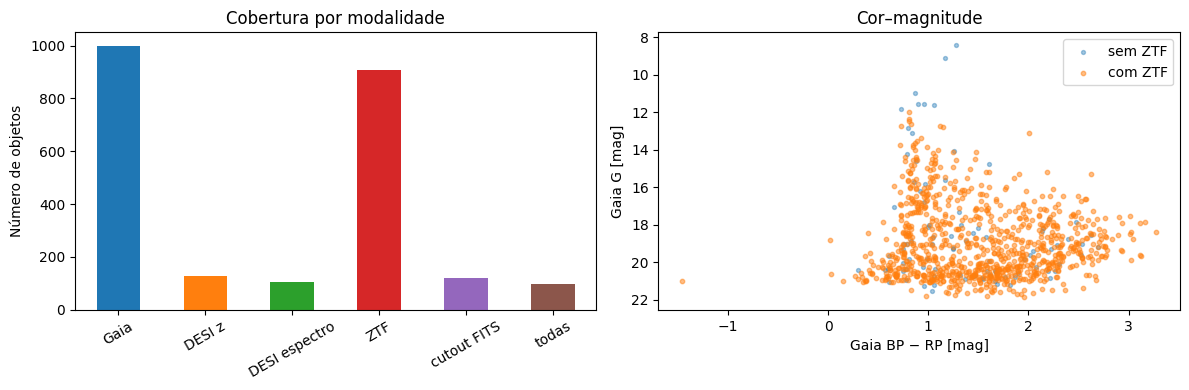

In [29]:
coverage = pd.Series({
    "Gaia": len(manifest),
    "DESI z": int(manifest.has_desi.sum()),
    "DESI espectro": int(manifest.has_desi_spectrum.sum()),
    "ZTF": int(manifest.has_ztf.sum()),
    "cutout FITS": int(manifest.stamp_status.eq("available").sum()),
    "todas": int(manifest.has_full_multimodal.sum()),
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
coverage.plot.bar(ax=axes[0], color=plt.cm.tab10.colors[:len(coverage)])
axes[0].set(ylabel="Número de objetos", title="Cobertura por modalidade")
axes[0].tick_params(axis="x", rotation=30)
axes[1].scatter(manifest.loc[~manifest.has_ztf, "bp_minus_rp"],
                manifest.loc[~manifest.has_ztf, "phot_g_mean_mag"],
                s=8, alpha=0.4, label="sem ZTF")
axes[1].scatter(manifest.loc[manifest.has_ztf, "bp_minus_rp"],
                manifest.loc[manifest.has_ztf, "phot_g_mean_mag"],
                s=10, alpha=0.5, label="com ZTF")
axes[1].invert_yaxis()
axes[1].set(xlabel="Gaia BP − RP [mag]", ylabel="Gaia G [mag]", title="Cor–magnitude")
axes[1].legend()
plt.tight_layout()
plt.show()


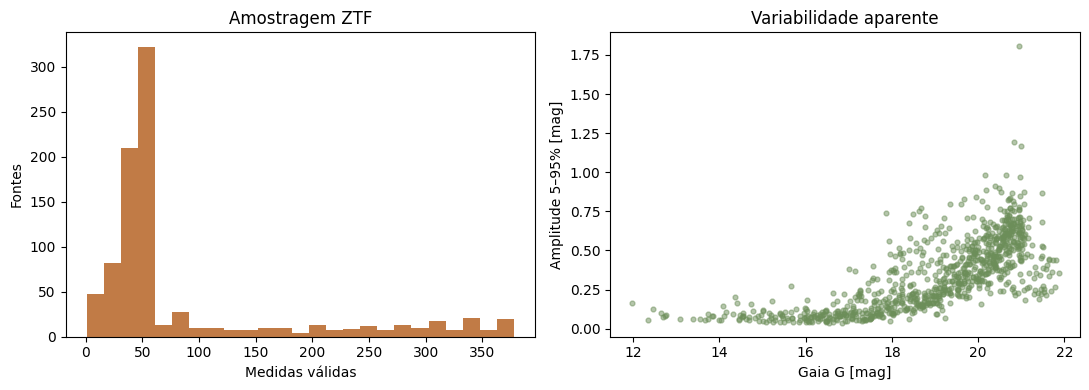

In [30]:
if manifest.has_ztf.any():
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    ztf_subset = manifest[manifest.has_ztf]
    axes[0].hist(ztf_subset["ztf_n_valid"].dropna(), bins=25, color="#c17b46")
    axes[0].set(xlabel="Medidas válidas", ylabel="Fontes", title="Amostragem ZTF")
    axes[1].scatter(ztf_subset["phot_g_mean_mag"], ztf_subset["ztf_amp90"],
                    s=12, alpha=0.5, color="#6c8e59")
    axes[1].set(xlabel="Gaia G [mag]", ylabel="Amplitude 5–95% [mag]",
                title="Variabilidade aparente")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhuma associação ZTF neste campo; escolha outro campo para ver estes gráficos.")

,object_id,source_id,ra,dec,pmra,pmdec,parallax,ruwe,desi_id,z,spectype,n_ztf_filters
0,gaia_2449825744794530432,2449825744794530432,0.002285,-0.950081,6.269929,-11.0904,0.316076,1.036513,39627760569679946,-0.000505,STAR,3


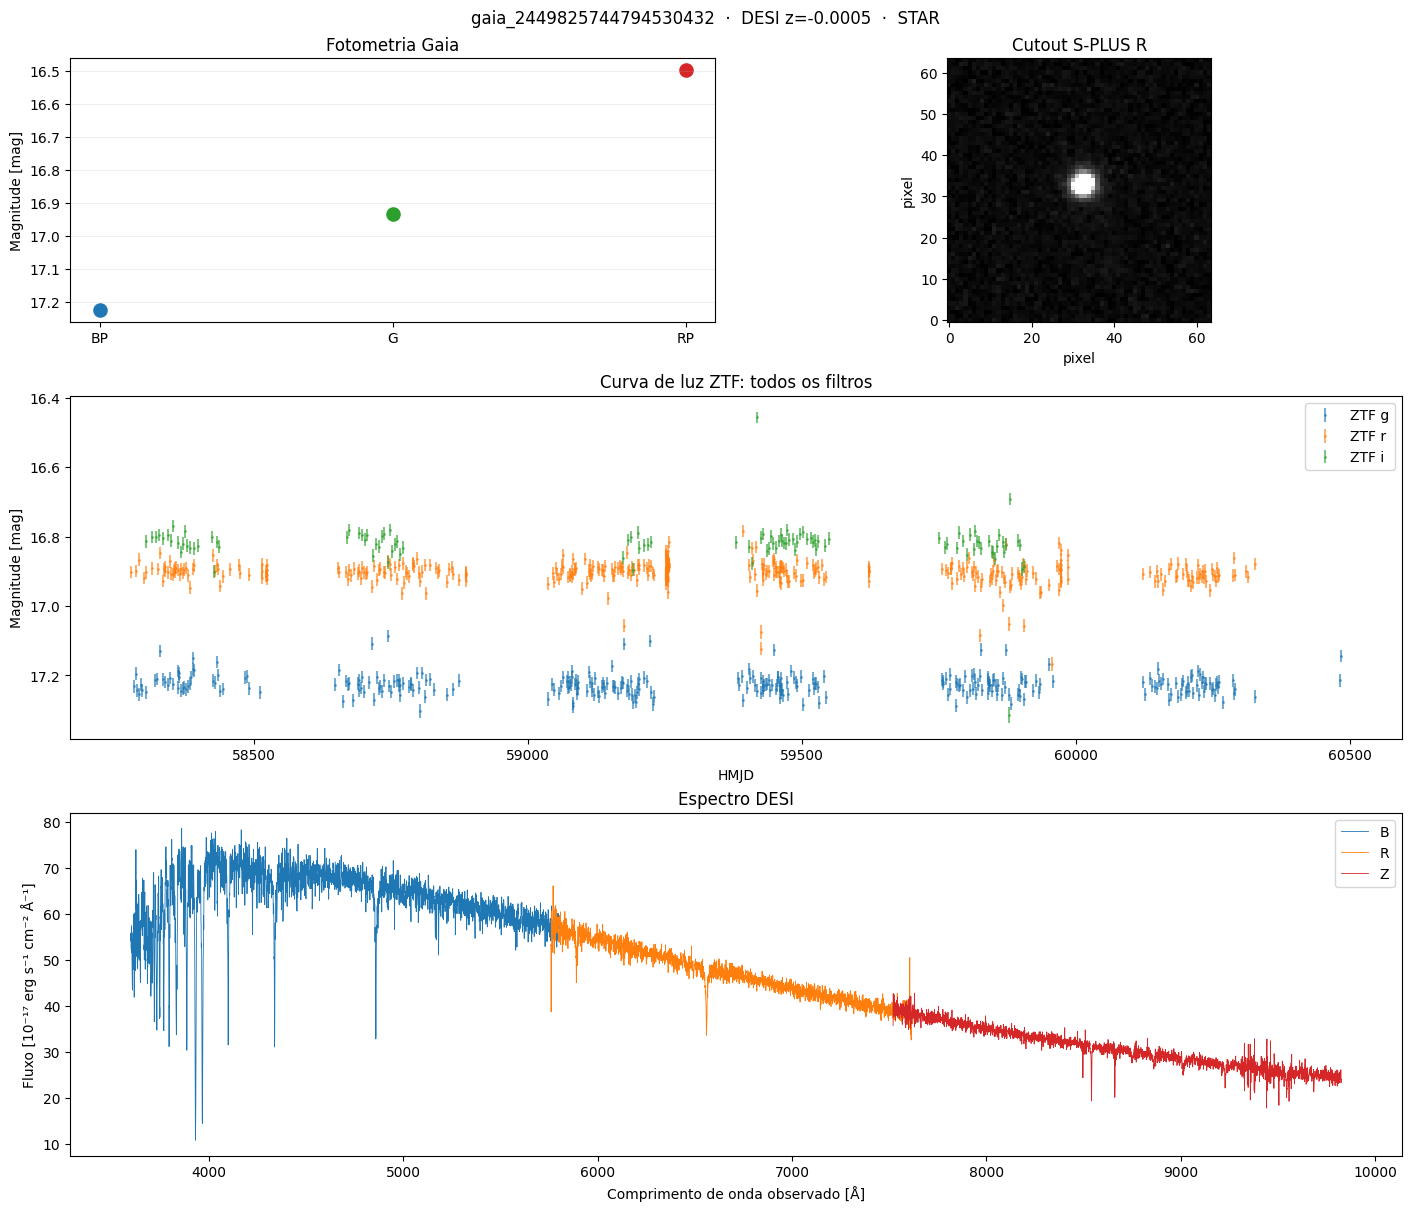

In [31]:
# Prefer full coverage with the most ZTF filters and valid measurements.
candidates = (manifest.loc[manifest.has_full_multimodal & manifest.ztf_n_valid.ge(5)]
              .sort_values(["n_ztf_filters", "ztf_n_valid"], ascending=[False, False]))
if candidates.empty:
    print("Nenhuma fonte com espectro DESI, curva ZTF válida e cutout disponível nesta amostra.")
else:
    example = candidates.iloc[0]
    object_id = example["object_id"]
    example_spectrum = spectra.loc[spectra.desi_id.eq(example["desi_id"]) & spectra.has_valid_flux].iloc[0]
    example_curves = raw_ztf.loc[raw_ztf.object_id.eq(object_id)]

    display(pd.DataFrame([example[["object_id", "source_id", "ra", "dec", "pmra",
                                   "pmdec", "parallax", "ruwe", "desi_id", "z",
                                   "spectype", "n_ztf_filters"]].to_dict()]))

    fig = plt.figure(figsize=(14, 12), constrained_layout=True)
    grid = fig.add_gridspec(3, 2, height_ratios=[1, 1.3, 1.3])
    ax_phot = fig.add_subplot(grid[0, 0])
    ax_image = fig.add_subplot(grid[0, 1])
    ax_ztf = fig.add_subplot(grid[1, :])
    ax_desi = fig.add_subplot(grid[2, :])

    # Gaia's three integrated-band magnitudes are separate from spectral flux.
    gaia_mags = [example["phot_bp_mean_mag"], example["phot_g_mean_mag"],
                 example["phot_rp_mean_mag"]]
    for band, magnitude, color in zip(("BP", "G", "RP"), gaia_mags,
                                      ("tab:blue", "tab:green", "tab:red")):
        if pd.notna(magnitude):
            ax_phot.scatter(band, magnitude, color=color, s=90)
    ax_phot.invert_yaxis()
    ax_phot.set(ylabel="Magnitude [mag]", title="Fotometria Gaia")
    ax_phot.grid(axis="y", alpha=0.2)

    with fits.open(example["stamp_path"]) as hdul:
        image = next(hdu.data for hdu in hdul if hdu.data is not None)
    lo, hi = np.nanpercentile(image, [5, 99.5])
    ax_image.imshow(image, origin="lower", cmap="gray", vmin=lo, vmax=hi)
    ax_image.set(title="Cutout S-PLUS R", xlabel="pixel", ylabel="pixel")

    filter_names = {1: "g", 2: "r", 3: "i"}
    for filter_id, rows in example_curves.groupby("filterid"):
        parts = []
        for _, row in rows.iterrows():
            t = np.asarray(row["hmjd"], dtype=float)
            mag = np.asarray(row["mag"], dtype=float)
            err = np.asarray(row["magerr"], dtype=float)
            if not (len(t) == len(mag) == len(err)):
                continue
            valid = np.isfinite(t) & np.isfinite(mag) & np.isfinite(err) & (err > 0)
            if valid.any():
                parts.append((t[valid], mag[valid], err[valid]))
        if parts:
            t, mag, err = (np.concatenate([part[i] for part in parts]) for i in range(3))
            ax_ztf.errorbar(t, mag, yerr=err, fmt=".", ms=2, alpha=0.6,
                            label=f"ZTF {filter_names.get(filter_id, filter_id)}")
    ax_ztf.invert_yaxis()
    ax_ztf.legend()
    ax_ztf.set(xlabel="HMJD", ylabel="Magnitude [mag]", title="Curva de luz ZTF: todos os filtros")

    for arm, color in (("b", "tab:blue"), ("r", "tab:orange"), ("z", "tab:red")):
        wave = np.asarray(example_spectrum[f"wave_{arm}"], dtype=float)
        flux = np.asarray(example_spectrum[f"flux_{arm}"], dtype=float)
        ivar = np.asarray(example_spectrum[f"ivar_{arm}"], dtype=float)
        if wave.ndim != 1 or wave.shape != flux.shape or wave.shape != ivar.shape:
            continue
        valid = np.isfinite(wave) & np.isfinite(flux) & np.isfinite(ivar) & (ivar > 0)
        if valid.any():
            ax_desi.plot(wave[valid], flux[valid], color=color, lw=0.6, label=arm.upper())
    ax_desi.legend()
    ax_desi.set(xlabel="Comprimento de onda observado [Å]",
                ylabel="Fluxo [10⁻¹⁷ erg s⁻¹ cm⁻² Å⁻¹]", title="Espectro DESI")
    fig.suptitle(f"{object_id}  ·  DESI z={example['z']:.4f}  ·  {example['spectype']}")
    plt.show()


## 9. Salvar e conferir

O CSV guarda uma linha por objeto e os caminhos dos produtos associados. `ztf_lightcurves.jsonl` guarda **todas** as linhas e filtros ZTF; `desi_spectra.jsonl` guarda os arrays de comprimento de onda, fluxo e variância inversa para as três câmeras DESI. O arquivo de proveniência registra consultas, parâmetros e data, sem credenciais.


In [32]:
summary = pd.DataFrame({
    "metric": ["objects", "with_desi", "with_desi_spectrum", "with_ztf",
               "full_multimodal", "secure_desi_z", "good_astrometry",
               "ambiguous_desi", "multiple_ztf_rows", "stamps_available"],
    "count": [len(manifest), int(manifest.has_desi.sum()),
              int(manifest.has_desi_spectrum.sum()), int(manifest.has_ztf.sum()),
              int(manifest.has_full_multimodal.sum()),
              int(manifest.has_secure_desi_z.sum()), int(manifest.has_good_astrometry.sum()),
              int(manifest.n_desi_candidates.gt(1).sum()),
              int(manifest.n_ztf_candidates.gt(1).sum()),
              int(manifest.stamp_status.eq("available").sum())],
})
display(summary)

# Store array-valued modalities separately to keep the one-row-per-source CSV small.
def json_array(values):
    if values is None:
        return None
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        return None
    return [float(x) if np.isfinite(x) else None for x in array]

curves_path = OUT / "ztf_lightcurves.jsonl"
with curves_path.open("w", encoding="utf-8") as handle:
    for _, row in raw_ztf.iterrows():
        record = {"object_id": row["object_id"], "ztf_id": str(row["ztf_id"]),
                  "filterid": None if pd.isna(row["filterid"]) else int(row["filterid"]),
                  "hmjd": json_array(row["hmjd"]),
                  "mag": json_array(row["mag"]),
                  "magerr": json_array(row["magerr"])}
        handle.write(json.dumps(record, allow_nan=False) + "\n")

spectra_path = OUT / "desi_spectra.jsonl"
with spectra_path.open("w", encoding="utf-8") as handle:
    for _, row in spectra.iterrows():
        record = {"desi_id": str(row["desi_id"]), "has_valid_flux": bool(row["has_valid_flux"])}
        for arm in ("b", "r", "z"):
            for quantity in ("wave", "flux", "ivar"):
                values = row[f"{quantity}_{arm}"]
                record[f"{quantity}_{arm}"] = json_array(values)
        handle.write(json.dumps(record, allow_nan=False) + "\n")

manifest["ztf_curve_file"] = np.where(manifest.has_ztf, str(curves_path), "")
manifest["desi_spectrum_file"] = np.where(manifest.has_desi_spectrum, str(spectra_path), "")
manifest_path = OUT / "manifest.csv"
manifest.to_csv(manifest_path, index=False)
provenance = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "base_url": BASE_URL,
    "adss_version": getattr(adss, "__version__", "unknown"),
    "gaia_query": gaia_query,
    "desi_query": desi_query,
    "desi_spectra_query": desi_spectra_query,
    "ztf_query": ztf_query,
    "collection_id": COLLECTION_ID,
    "image_file_id": int(image_file["id"]),
    "image_filename": image_file["filename"],
    "match_radius_arcsec": MATCH_RADIUS_ARCSEC,
    "polygon_vertices_ra_dec_deg": [[POLYGON_RA_WEST, POLYGON_DEC_SOUTH],
                                   [POLYGON_RA_EAST, POLYGON_DEC_SOUTH],
                                   [POLYGON_RA_EAST, POLYGON_DEC_NORTH],
                                   [POLYGON_RA_WEST, POLYGON_DEC_NORTH]],
    "max_objects": MAX_OBJECTS,
    "stamp_size_px": STAMP_PIXELS,
    "max_cutouts": MAX_CUTOUTS,
    "match_rule": "nearest angular separation for manifest; all ZTF filters retained in JSONL",
}
(OUT / "provenance.json").write_text(json.dumps(provenance, indent=2, ensure_ascii=False))
print("Salvos:", manifest_path, curves_path, spectra_path, OUT / "provenance.json")


,metric,count
0,objects,1000
1,with_desi,126
2,with_desi_spectrum,104
3,with_ztf,908
4,full_multimodal,98
5,secure_desi_z,117
6,good_astrometry,800
7,ambiguous_desi,9
8,multiple_ztf_rows,829
9,stamps_available,120


Salvos: outputs/multimodal/manifest.csv outputs/multimodal/ztf_lightcurves.jsonl outputs/multimodal/desi_spectra.jsonl outputs/multimodal/provenance.json


## Exercícios

1. Compare a magnitude G de fontes com e sem ZTF. A ausência de ZTF parece aleatória?
2. Inspecione fontes com `n_desi_candidates > 1` ou `n_ztf_candidates > 1`. Mude o raio de associação para 0,5 arcsec: quantas associações permanecem?
3. Escolha três curvas de luz com maior `ztf_amp90`. Todas parecem variáveis reais? Examine erros e pontos isolados.
4. Para um dataset de treino maior, aumente `MAX_OBJECTS` e baixe cutouts em lotes. Separe treino/teste por região do céu ou campo de imagem para reduzir vazamento. Registre a seleção e a versão dos dados.